In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("/content/StudentsPerformance.csv")

print("Dataset Loaded Successfully")

display(df.head())

Dataset Loaded Successfully


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()


Dataset Shape:
(1000, 8)

Column Names:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [5]:
print("\nStatistical Summary:")
display(df.describe())

# 5. Check Missing Values

print("\nMissing Values:")
print(df.isnull().sum())

# 6. Check Duplicate Values

print("\nDuplicate Records:")
print(df.duplicated().sum())


Statistical Summary:


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



Missing Values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Duplicate Records:
0


In [6]:
df["Total Score"] = (
    df["math score"]
    + df["reading score"]
    + df["writing score"]
)

In [7]:
df["Percentage"] = (
    df["Total Score"] / 300
) * 100


In [8]:
df["Average Score"] = df[
    ["math score", "reading score", "writing score"]
].mean(axis=1)

print("\nTotal Score, Percentage and Average:")
display(df.head())


Total Score, Percentage and Average:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Score,Percentage,Average Score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333,76.333333



Subject-wise Average:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64


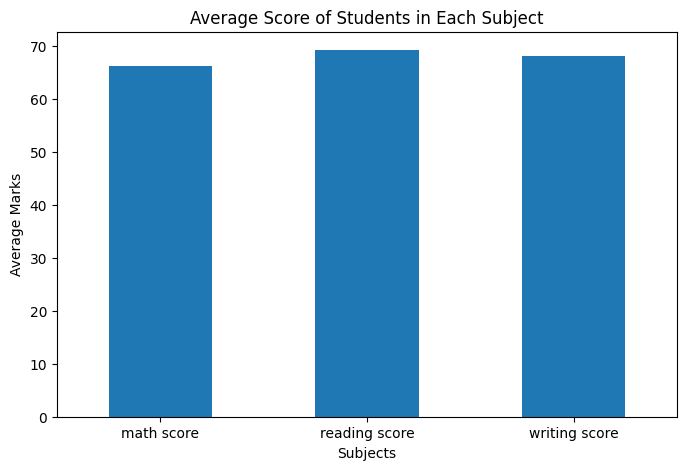

In [10]:
score_columns = [
    "math score",
    "reading score",
    "writing score"
]

subject_average = df[score_columns].mean()

print("\nSubject-wise Average:")
print(subject_average)

plt.figure(figsize=(8, 5))

subject_average.plot(kind="bar")

plt.title("Average Score of Students in Each Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)

plt.savefig("subject_average.png", dpi=300,
            bbox_inches="tight")

plt.show()



Gender-wise Average Scores:


,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


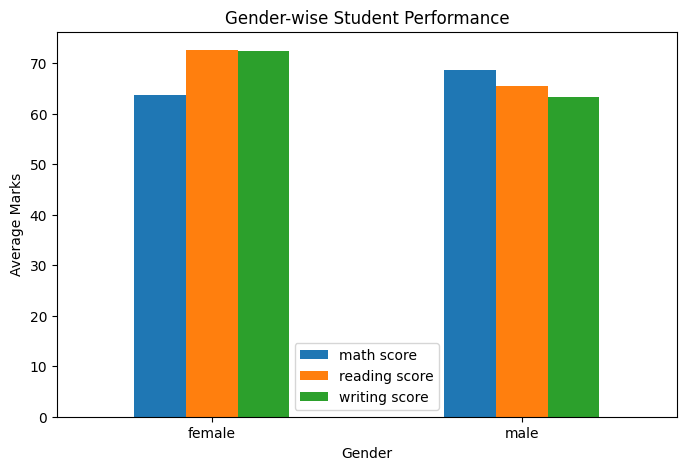

In [11]:
gender_average = df.groupby("gender")[score_columns].mean()

print("\nGender-wise Average Scores:")
display(gender_average)

gender_average.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Gender-wise Student Performance")
plt.xlabel("Gender")
plt.ylabel("Average Marks")
plt.xticks(rotation=0)

plt.savefig("gender_performance.png", dpi=300,
            bbox_inches="tight")

plt.show()


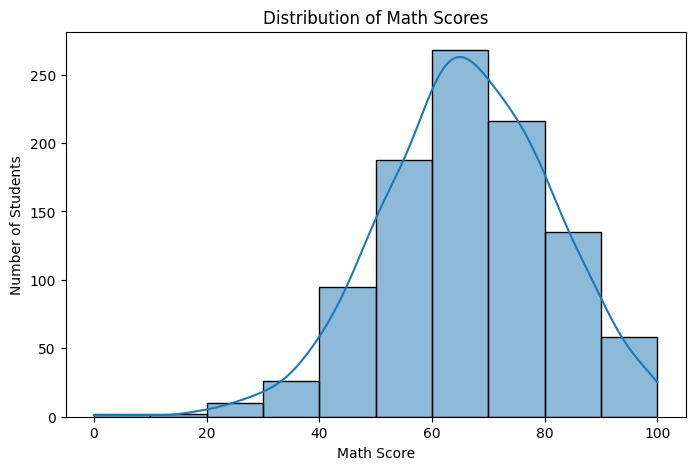

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["math score"],
    bins=10,
    kde=True
)

plt.title("Distribution of Math Scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")

plt.savefig("math_distribution.png", dpi=300,
            bbox_inches="tight")

plt.show()

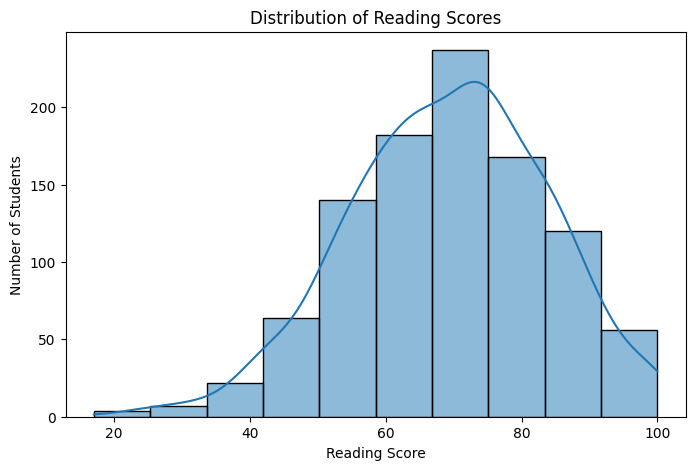

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["reading score"],
    bins=10,
    kde=True
)

plt.title("Distribution of Reading Scores")
plt.xlabel("Reading Score")
plt.ylabel("Number of Students")

plt.savefig("reading_distribution.png", dpi=300,
            bbox_inches="tight")

plt.show()

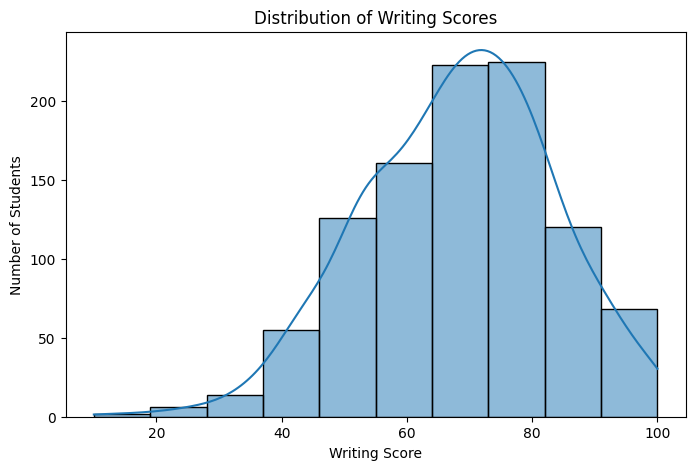

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["writing score"],
    bins=10,
    kde=True
)

plt.title("Distribution of Writing Scores")
plt.xlabel("Writing Score")
plt.ylabel("Number of Students")

plt.savefig("writing_distribution.png", dpi=300,
            bbox_inches="tight")

plt.show()

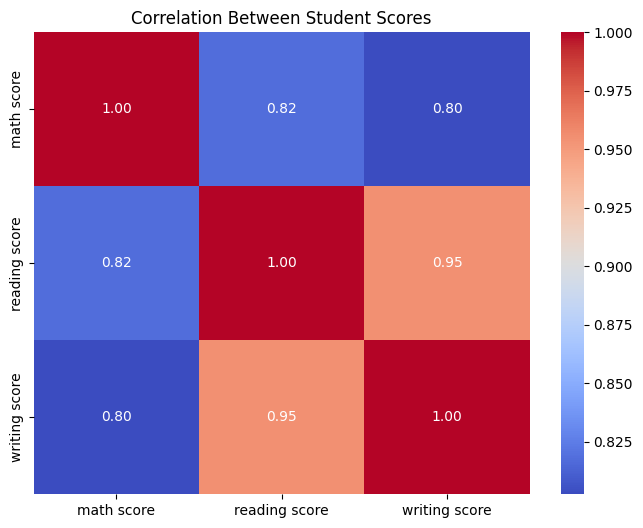

In [16]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df[score_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Student Scores")

plt.savefig("correlation_heatmap.png", dpi=300,
            bbox_inches="tight")

plt.show()


In [19]:
print("\nFinal Dataset:")
display(df.head(10))

print("\nEDA Completed Successfully!")


Final Dataset:


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,Total Score,Percentage,Average Score,Pass/Fail
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667,72.666667,Pass
1,female,group C,some college,standard,completed,69,90,88,247,82.333333,82.333333,Pass
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667,92.666667,Pass
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333,49.333333,Pass
4,male,group C,some college,standard,none,76,78,75,229,76.333333,76.333333,Pass
5,female,group B,associate's degree,standard,none,71,83,78,232,77.333333,77.333333,Pass
6,female,group B,some college,standard,completed,88,95,92,275,91.666667,91.666667,Pass
7,male,group B,some college,free/reduced,none,40,43,39,122,40.666667,40.666667,Fail
8,male,group D,high school,free/reduced,completed,64,64,67,195,65.000000,65.000000,Pass
9,female,group B,high school,free/reduced,none,38,60,50,148,49.333333,49.333333,Fail



EDA Completed Successfully!
